# Protein Subcellular Localization with ESM-2 Embeddings

Multi-label prediction of **Gene Ontology Cellular Component (GO CC)** terms from
protein sequence, followed by a geometric analysis of the linear probe that
performs the prediction.

**Pipeline**

1. Download reviewed (Swiss-Prot) proteins from the UniProt REST API.
2. Clean the records and keep those with at least one GO CC annotation.
3. Keep the 75 GO CC terms that occur in at least 100 proteins.
4. Embed every sequence with ESM-2 (`esm2_t12_35M_UR50D`, layer 12, mean-pooled).
5. Fit one-vs-rest logistic regression (a linear probe) on the embeddings.
6. Analyse the geometry of the resulting 75 x 480 weight matrix with SVD-based
   concentration measures, label co-occurrence statistics and permutation nulls.

**Regions**

| Region | Content |
| --- | --- |
| 0 | Environment setup |
| 1 | Data acquisition from UniProt |
| 2 | Dataset construction and label selection |
| 3 | Multi-label target matrix |
| 4 | ESM-2 protein embeddings |
| 5 | Linear probe: training, evaluation, weights |
| 6 | Spectral geometry of the probe weights |
| 7 | Label co-occurrence vs. probe geometry |
| 8 | Null models and permutation tests |
| 9 | Artifact inventory |
| 10 | Summary and limitations |

Cells are meant to be run top to bottom in a fresh kernel. Sections 1, 4 and 8
dominate runtime (10k API records, ESM-2 inference, and hundreds of probe refits
respectively); the artifacts in `protein_dataset/` can be reused to skip sections
1 to 4. All generated files and their schemas are documented in
[`protein_dataset/README.md`](protein_dataset/README.md).

The stored outputs come from a CPU run and are kept for reference; re-running the
notebook from a fresh kernel reproduces them.

## 0. Environment setup

Install the download and table dependencies, then the widget backend used by
`tqdm` progress bars. The notebook was executed on CPU with Python 3.13, so no
GPU-specific packages are required; `torch` selects the device automatically in
section 4.

In [7]:
%pip install requests pandas

Note: you may need to restart the kernel to use updated packages.


In [34]:
%pip install -U ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 40.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]
Note: you may need to restart the kernel to use updated packages.


In [6]:
import shutil
from pathlib import Path

total, used, free = shutil.disk_usage(Path.cwd())

print(f"Free disk space: {free / 1024**3:.2f} GB")

Free disk space: 205.18 GB


In [8]:
import re
import time
import requests
import pandas as pd
from pathlib import Path
from io import StringIO

print("Libraries loaded successfully")

Libraries loaded successfully


## 1. Data acquisition from UniProt

We query the UniProtKB REST endpoint for reviewed (Swiss-Prot) entries and ask
for three fields: `accession`, `sequence` and `go_c` (Gene Ontology annotations).
The GO Cellular Component terms live inside the `go_c` field and are parsed into
labels in section 2.3.

UniProt treats `go_c` as a returned field rather than a search field, so it cannot
be used inside the query string. The first cell documents that behaviour; the
actual download therefore requests `reviewed:true` and filters on the returned
annotation text.

### 1.1 Probe the API

A deliberately invalid query (`reviewed:true AND go_c:*`) to show that `go_c` is
not queryable. The endpoint answers with HTTP 400 and an error message, which
confirms that filtering has to happen after download.

In [10]:
import requests

url = "https://rest.uniprot.org/uniprotkb/search"

params = {
    "query": "reviewed:true AND go_c:*",
    "format": "tsv",
    "fields": "accession,sequence,go_c",
    "size": 5,
}

response = requests.get(url, params=params, timeout=60)

print("Status code:", response.status_code)
print("Response message:")
print(response.text[:2000])

Status code: 400
Response message:
Error messages
'go_c' is not a valid search field


### 1.2 Inspect the TSV schema

Fetch five reviewed entries with only the accession and sequence fields and parse
the tab-separated response with pandas. This fixes the column names used
throughout the notebook.

In [11]:
import requests
import pandas as pd
from io import StringIO

url = "https://rest.uniprot.org/uniprotkb/search"

params = {
    "query": "reviewed:true",
    "format": "tsv",
    "fields": "accession,sequence",
    "size": 5,
}

response = requests.get(url, params=params, timeout=60)
print("Status:", response.status_code)

response.raise_for_status()

test_df = pd.read_csv(StringIO(response.text), sep="\t")
display(test_df.head())
print(test_df.columns.tolist())

Status: 200


,Entry,Sequence
0,A0A0C5B5G6,MRWQEMGYIFYPRKLR
1,A0A1B0GTW7,MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKS...
2,A0JNW5,MAGIIKKQILKHLSRFTKNLSPDKINLSTLKGEGELKNLELDEEVL...
3,A0JP26,MVAEVCSMPAASAVKKPFDLRSKMGKWCHHRFPCCRGSGKSNMGTS...
4,A0PK11,MPGWFKKAWYGLASLLSFSSFILIIVALVVPHWLSGKILCQTGVDL...


['Entry', 'Sequence']


### 1.3 Inspect the GO CC annotations

Add the `go_c` field and look at the raw text before parsing it. Each annotation
is written as `term name [GO:xxxxxxx]` and several terms are separated by
semicolons.

In [13]:
params = {
    "query": "reviewed:true",
    "format": "tsv",
    "fields": "accession,sequence,go_c",
    "size": 500,
}

response = requests.get(url, params=params, timeout=60)

print("Status:", response.status_code)
print(response.text[:1000])

Status: 200
Entry	Sequence	Gene Ontology (cellular component)
A0A0C5B5G6	MRWQEMGYIFYPRKLR	extracellular region [GO:0005576]; mitochondrion [GO:0005739]; nucleus [GO:0005634]
A0A1B0GTW7	MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKSRSSSLTLPSSRDPQPLRIQSCYLGDHISDGAWDPEGEGMRGGSRALAAVREATQRIQAVLAVQGPLLLSRDPAQYCHAVWGDPDSPNYHRCSLLNPGYKGESCLGAKIPDTHLRGYALWPEQGPPQLVQPDGPGVQNTDFLLYVRVAHTSKCHQETVSLCCPGWSTAAQSQLTAALTSWAQRRGFVMLPRLCLKLLGSSNLPTLASQSIRITGPSVIAYAACCQLDSEDRPLAGTIVYCAQHLTSPSLSHSDIVMATLHELLHALGFSGQLFKKWRDCPSGFSVRENCSTRQLVTRQDEWGQLLLTTPAVSLSLAKHLGVSGASLGVPLEEEEGLLSSHWEARLLQGSLMTATFDGAQRTRLDPITLAAFKDSGWYQVNHSAAEELLWGQGSGPEFGLVTTCGTGSSDFFCTGSGLGCHYLHLDKGSCSSDPMLEGCRMYKPLANGSECWKKENGFPAGVDNPHGEIYHPQSRCFFANLTSQLLPGDKPRHPSLTPHLKEAELMGRCYLHQCTGRGAYKVQVEGSPWVPCLPGKVIQIPGYYGLLFCPRGRLCQTNEDINAVTSPPVSLSTPDPLFQLSLELAGPPGHSLGKEQQEGLAEAVLEALASKGGTGRCYFHGPSITTSLVFTVHMWKSPGCQGPSVATLHKALTLTLQKKPLEVYHGGANFTTQPSKLLVTSDHNPSMTHLRLSMGLCLMLLILVGVMGTTAYQKRATLPVRPSASYHSPELHSTRVPVRGIREV	cytoplasm [GO:0005737]; me

In [14]:
response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

test_df = pd.read_csv(StringIO(response.text), sep="\t")

print("Columns:", test_df.columns.tolist())
display(test_df.head())

Columns: ['Entry', 'Sequence', 'Gene Ontology (cellular component)']


,Entry,Sequence,Gene Ontology (cellular component)
0,A0A0C5B5G6,MRWQEMGYIFYPRKLR,extracellular region [GO:0005576]; mitochondri...
1,A0A1B0GTW7,MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKS...,cytoplasm [GO:0005737]; membrane [GO:0016020]
2,A0JNW5,MAGIIKKQILKHLSRFTKNLSPDKINLSTLKGEGELKNLELDEEVL...,cytosol [GO:0005829]; early endosome [GO:0005769]
3,A0JP26,MVAEVCSMPAASAVKKPFDLRSKMGKWCHHRFPCCRGSGKSNMGTS...,NaN
4,A0PK11,MPGWFKKAWYGLASLLSFSSFILIIVALVVPHWLSGKILCQTGVDL...,stereocilium bundle [GO:0032421]; stereocilium...


### 1.4 Dry-run the cleaning on the sample

Before downloading 10,000 records, apply the same column mapping and filter to the
500-record sample. The renaming fixes the three column names used by the rest of the
notebook (`uniprot_id`, `sequence`, `go_cc_raw`), and the filter shows that 495 of
the 500 rows carry at least one GO CC annotation.

In [21]:
df = test_df.copy()

df = df.rename(columns={
    "Entry": "uniprot_id",
    "Sequence": "sequence",
    "Gene Ontology (cellular component)": "go_cc_raw"
})

print(df.columns.tolist())
display(df.head())


['uniprot_id', 'sequence', 'go_cc_raw']


,uniprot_id,sequence,go_cc_raw
0,A0A0C5B5G6,MRWQEMGYIFYPRKLR,extracellular region [GO:0005576]; mitochondri...
1,A0A1B0GTW7,MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKS...,cytoplasm [GO:0005737]; membrane [GO:0016020]
2,A0JNW5,MAGIIKKQILKHLSRFTKNLSPDKINLSTLKGEGELKNLELDEEVL...,cytosol [GO:0005829]; early endosome [GO:0005769]
3,A0JP26,MVAEVCSMPAASAVKKPFDLRSKMGKWCHHRFPCCRGSGKSNMGTS...,NaN
4,A0PK11,MPGWFKKAWYGLASLLSFSSFILIIVALVVPHWLSGKILCQTGVDL...,stereocilium bundle [GO:0032421]; stereocilium...


In [22]:
df["go_cc_raw"] = df["go_cc_raw"].fillna("")
df = df[df["go_cc_raw"].str.strip() != ""].copy()

print("Proteins with GO CC annotations:", len(df))

Proteins with GO CC annotations: 495


### 1.5 Full download with pagination

UniProt returns at most 500 records per response and exposes the next page through
the `Link` header. The loop below follows `response.links["next"]` until either no
page is left or the 10,000-record cap is reached. The cap keeps the experiment
lightweight; it means the dataset is a prefix of reviewed Swiss-Prot, not the full
database.

In [23]:
import requests
import pandas as pd
import time
from io import StringIO
from pathlib import Path

url = "https://rest.uniprot.org/uniprotkb/search"

params = {
    "query": "reviewed:true",
    "format": "tsv",
    "fields": "accession,sequence,go_c",
    "size": 500,
}

MAX_RECORDS = 10_000
records = []
next_url = url
first_request = True

while next_url and len(records) < MAX_RECORDS:
    response = requests.get(
        next_url,
        params=params if first_request else None,
        timeout=120
    )
    response.raise_for_status()

    page = pd.read_csv(StringIO(response.text), sep="\t")

    if page.empty:
        break

    records.extend(page.to_dict("records"))
    print(f"Downloaded: {len(records):,}")

    next_url = response.links.get("next", {}).get("url")
    first_request = False
    time.sleep(0.2)

df = pd.DataFrame(records[:MAX_RECORDS])

print("Total downloaded:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Downloaded: 500
Downloaded: 1,000
Downloaded: 1,500
Downloaded: 2,000
Downloaded: 2,500
Downloaded: 3,000
Downloaded: 3,500
Downloaded: 4,000
Downloaded: 4,500
Downloaded: 5,000
Downloaded: 5,500
Downloaded: 6,000
Downloaded: 6,500
Downloaded: 7,000
Downloaded: 7,500
Downloaded: 8,000
Downloaded: 8,500
Downloaded: 9,000
Downloaded: 9,500
Downloaded: 10,000
Total downloaded: 10000
Columns: ['Entry', 'Sequence', 'Gene Ontology (cellular component)']


,Entry,Sequence,Gene Ontology (cellular component)
0,A0A0C5B5G6,MRWQEMGYIFYPRKLR,extracellular region [GO:0005576]; mitochondri...
1,A0A1B0GTW7,MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKS...,cytoplasm [GO:0005737]; membrane [GO:0016020]
2,A0JNW5,MAGIIKKQILKHLSRFTKNLSPDKINLSTLKGEGELKNLELDEEVL...,cytosol [GO:0005829]; early endosome [GO:0005769]
3,A0JP26,MVAEVCSMPAASAVKKPFDLRSKMGKWCHHRFPCCRGSGKSNMGTS...,NaN
4,A0PK11,MPGWFKKAWYGLASLLSFSSFILIIVALVVPHWLSGKILCQTGVDL...,stereocilium bundle [GO:0032421]; stereocilium...


## 2. Dataset construction

The raw download is normalised into a three-column table, filtered to proteins
with at least one GO CC annotation, and reduced to GO terms that are frequent
enough to learn from.

### 2.1 Normalise the columns and filter

Rename the UniProt headers to snake_case, drop rows without an ID or sequence, and
keep only proteins whose GO CC field is non-empty. The result (9,895 of the 10,000
downloaded records) is written to `protein_dataset/uniprot_swissprot_go_cc.csv`.

In [24]:
df = df.rename(columns={
    "Entry": "uniprot_id",
    "Sequence": "sequence",
    "Gene Ontology (cellular component)": "go_cc_raw"
})

df["go_cc_raw"] = df["go_cc_raw"].fillna("")

df = df.dropna(subset=["uniprot_id", "sequence"])
df = df[df["go_cc_raw"].str.strip() != ""].copy()

output_dir = Path("protein_dataset")
output_dir.mkdir(exist_ok=True)

df.to_csv(
    output_dir / "uniprot_swissprot_go_cc.csv",
    index=False
)

print("Proteins with GO CC annotations:", len(df))
print("Saved to:", output_dir / "uniprot_swissprot_go_cc.csv")

Proteins with GO CC annotations: 9895
Saved to: protein_dataset/uniprot_swissprot_go_cc.csv


### 2.2 Quality control

Check the size of the table, the presence of missing values, and duplicate
accessions before any modelling happens.

In [26]:
print("Total records:", len(df))
print("Columns:", df.columns.tolist())

print("Missing UniProt IDs:", df["uniprot_id"].isna().sum())
print("Missing sequences:", df["sequence"].isna().sum())
print("Missing GO annotations:", df["go_cc_raw"].fillna("").str.strip().eq("").sum())

print("Duplicate UniProt IDs:", df["uniprot_id"].duplicated().sum())

Total records: 9895
Columns: ['uniprot_id', 'sequence', 'go_cc_raw']
Missing UniProt IDs: 0
Missing sequences: 0
Missing GO annotations: 0
Duplicate UniProt IDs: 0


### 2.3 Parse GO IDs and count label frequencies

Extract the GO identifiers with a regular expression, deduplicate them per protein,
and count how many proteins carry each term. The export contains 1,779 distinct GO
CC terms, with a strongly skewed frequency distribution: the most frequent term
(nucleus, `GO:0005634`) has 3,360 proteins while most terms have only a handful.

In [27]:
import re
from collections import Counter

df["go_cc_ids"] = df["go_cc_raw"].fillna("").apply(
    lambda text: sorted(set(re.findall(r"GO:\d{7}", text)))
)

df = df[df["go_cc_ids"].map(len) > 0].copy()

go_counts = Counter(
    go_id
    for labels in df["go_cc_ids"]
    for go_id in labels
)

label_counts = (
    pd.DataFrame(
        go_counts.items(),
        columns=["go_id", "protein_count"]
    )
    .sort_values("protein_count", ascending=False)
    .reset_index(drop=True)
)

display(label_counts.head(20))
print("Unique GO CC labels:", len(label_counts))

,go_id,protein_count
0,GO:0005634,3360
1,GO:0005829,3291
2,GO:0005737,3210
3,GO:0005886,2890
4,GO:0005654,2314
5,GO:0016020,1839
6,GO:0005576,1460
7,GO:0070062,1439
8,GO:0005739,932
9,GO:0005789,754


Unique GO CC labels: 1779


### 2.4 Select labels for modelling

Terms that appear in fewer than 100 proteins cannot be learned reliably, so the
threshold `MIN_POSITIVES = 100` keeps 75 labels. Both the full frequency table and
the selected label list are saved so later sections do not depend on this cell
having run in the same session.

In [28]:
MIN_POSITIVES = 100

selected_labels = label_counts.loc[
    label_counts["protein_count"] >= MIN_POSITIVES,
    "go_id"
].tolist()

print("Selected labels:", len(selected_labels))
print(selected_labels[:20])

label_counts.to_csv(
    "protein_dataset/go_cc_label_counts.csv",
    index=False
)

pd.DataFrame({"go_id": selected_labels}).to_csv(
    "protein_dataset/selected_go_labels.csv",
    index=False
)

Selected labels: 75
['GO:0005634', 'GO:0005829', 'GO:0005737', 'GO:0005886', 'GO:0005654', 'GO:0016020', 'GO:0005576', 'GO:0070062', 'GO:0005739', 'GO:0005789', 'GO:0005783', 'GO:0000785', 'GO:0005794', 'GO:0005730', 'GO:0009986', 'GO:0048471', 'GO:0000139', 'GO:0032991', 'GO:0098978', 'GO:0005813']


### 2.5 Inspect the label count table

Reload the saved frequency table to confirm the file was written correctly and to
see the label distribution that the 100-protein threshold operates on.

In [51]:
import pandas as pd

counts_df = pd.read_csv(
    "protein_dataset/go_cc_label_counts.csv"
)

print("Shape:", counts_df.shape)
print("Columns:", counts_df.columns.tolist())
print(counts_df.head(10).to_string(index=False))

Shape: (1779, 2)
Columns: ['go_id', 'protein_count']
     go_id  protein_count
GO:0005634           3360
GO:0005829           3291
GO:0005737           3210
GO:0005886           2890
GO:0005654           2314
GO:0016020           1839
GO:0005576           1460
GO:0070062           1439
GO:0005739            932
GO:0005789            754


## 3. Multi-label target matrix

Each protein is described by a binary vector of length 75, with a 1 for every
selected GO CC term it is annotated with. The result is a sparse 9,895 x 75 matrix
`Y` with 36,188 positive entries (3.66 labels per protein). Terms are kept in the
descending-frequency order of section 2.3, and that order defines the column order
everywhere else in the notebook.

Note that 9,786 proteins carry at least one selected label; the remaining 109 rows
are all-zero and contribute nothing to the supervised loss.

In [29]:
import numpy as np
import pandas as pd
from pathlib import Path

# Load the labels selected in section 2.4.
selected_labels = pd.read_csv(
    "protein_dataset/selected_go_labels.csv"
)["go_id"].tolist()

# Build the N x 75 multi-label target matrix: one column per selected GO term.
label_to_index = {
    go_id: i for i, go_id in enumerate(selected_labels)
}

Y = np.zeros(
    (len(df), len(selected_labels)),
    dtype=np.float32
)

for row_idx, labels in enumerate(df["go_cc_ids"]):
    for go_id in labels:
        if go_id in label_to_index:
            Y[row_idx, label_to_index[go_id]] = 1.0

print("Y shape:", Y.shape)
print("Positive labels:", int(Y.sum()))
print("Labels per protein (mean):", Y.sum(axis=1).mean())
print("Proteins with at least one selected label:",
      int((Y.sum(axis=1) > 0).sum()))

Y shape: (9895, 75)
Positive labels: 36188
Labels per protein (mean): 3.6572006
Proteins with at least one selected label: 9786


## 4. ESM-2 protein embeddings

The sequences are embedded with ESM-2 (`esm2_t12_35M_UR50D`, 35M parameters, 12
transformer layers). The 480-dimensional representation of each protein is the
mean of the layer-12 states over its residues, excluding the BOS and EOS tokens.

Mean pooling over the last layer is a simple and widely used baseline; section 10
lists alternatives such as per-layer pooling or attention-weighted pooling.

### 4.1 Load the model

Download the pretrained checkpoint, build the tokeniser (`alphabet`) and move the
model to the available device.

In [30]:
import torch
import esm
import numpy as np

model, alphabet = esm.pretrained.esm2_t12_35M_UR50D()
model.eval()

batch_converter = alphabet.get_batch_converter()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Device:", device)
print("Model loaded successfully")

Device: cpu
Model loaded successfully


### 4.2 Compute mean-pooled embeddings

Sequences are truncated to 1,022 residues to stay inside the model context window,
processed four at a time, and mean-pooled per protein. On CPU this takes roughly 42
minutes for the 9,895 sequences.

In [31]:
from tqdm.auto import tqdm
import numpy as np
import torch

# Protein IDs and sequences, in the same row order as the target matrix.
protein_ids = df["uniprot_id"].tolist()
sequences = df["sequence"].tolist()

# Batch size 4 keeps memory low; drop to 1-2 if the machine runs out of RAM.
BATCH_SIZE = 4
MAX_LENGTH = 1022  # below the ESM-2 context limit, leaving room for special tokens

all_embeddings = []

model.eval()

with torch.no_grad():
    for start in tqdm(range(0, len(sequences), BATCH_SIZE)):
        batch_ids = protein_ids[start:start + BATCH_SIZE]
        batch_seqs = sequences[start:start + BATCH_SIZE]

        # Truncate sequences that are longer than the model can consume.
        batch_data = [
            (pid, seq[:MAX_LENGTH])
            for pid, seq in zip(batch_ids, batch_seqs)
        ]

        _, _, tokens = batch_converter(batch_data)
        tokens = tokens.to(device)

        results = model(
            tokens,
            repr_layers=[12],
            return_contacts=False
        )

        representations = results["representations"][12]

        for i, seq in enumerate(batch_data):
            # Token 0 is BOS and the final token is EOS; average the residues only.
            seq_len = len(seq[1])
            embedding = representations[i, 1:seq_len + 1].mean(dim=0)
            all_embeddings.append(embedding.cpu().numpy())

X = np.stack(all_embeddings).astype(np.float32)

print("X shape:", X.shape)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|███████████████████████████████████████████████████████████████████████████████| 2474/2474 [42:26<00:00,  1.03s/it]

X shape: (9895, 480)


### 4.3 Sanity check

Confirm that the embedding matrix exists, has the expected shape and dtype, and
contains no NaN values.

In [32]:
print("X exists:", "X" in globals())

if "X" in globals():
    print("X shape:", X.shape)
    print("Data type:", X.dtype)
    print("Has NaN:", np.isnan(X).any())

X exists: True
X shape: (9895, 480)
Data type: float32
Has NaN: False


### 4.4 Persist embeddings and targets

Write the embedding matrix, the label matrix and the protein ID order to
`protein_dataset/`. Keeping the ID table makes the row order of both arrays
explicit and reproducible.

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path("protein_dataset")
output_dir.mkdir(exist_ok=True)

np.save(output_dir / "esm2_embeddings.npy", X)
np.save(output_dir / "go_labels.npy", Y)

pd.DataFrame({
    "uniprot_id": protein_ids
}).to_csv(output_dir / "protein_ids.csv", index=False)

print("Saved successfully!")
print("Embedding shape:", X.shape)
print("Label shape:", Y.shape)

Saved successfully!
Embedding shape: (9895, 480)
Label shape: (9895, 75)


## 5. Linear probe

A one-vs-rest logistic regression is trained on the embeddings, one binary
classifier per GO term. Standardisation is part of the pipeline, so the 480
embedding dimensions are centred and scaled before the linear model sees them.

The probe answers a specific question: how much of the annotation signal is
linearly decodable from the frozen ESM-2 representation? Its weight matrix is the
object analysed in sections 6 to 8.

### 5.1 Train/test split

An 80/20 split with a fixed seed gives 7,916 training and 1,979 test proteins.
Labels are multi-label and imbalanced, so the split is stratified only implicitly;
section 10 notes cross-validation as the more robust alternative.

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: (7916, 480)
X_test: (1979, 480)
Y_train: (7916, 75)
Y_test: (1979, 75)


### 5.2 Train the probe

`class_weight="balanced"` compensates for the rarity of most GO terms, and
`OneVsRestClassifier` trains the 75 binary problems in parallel.

In [37]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

probe = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            class_weight="balanced"
        ),
        n_jobs=-1
    )
)

probe.fit(X_train, Y_train)

print("Linear probe training complete.")

Linear probe training complete.


### 5.3 Evaluate on the test set

ROC-AUC and average precision are computed per label and then averaged, skipping
labels for which the test fold happens to contain a single class. The probe
reaches a mean ROC-AUC of about 0.784 and a mean average precision of about 0.223;
the gap between the two reflects how imbalanced the labels are.

In [38]:
Y_score = probe.predict_proba(X_test)

aucs = []
aps = []

for j in range(Y_test.shape[1]):
    # ROC-AUC is undefined unless the test fold contains both classes for this label.
    if len(set(Y_test[:, j])) < 2:
        continue

    aucs.append(roc_auc_score(Y_test[:, j], Y_score[:, j]))
    aps.append(average_precision_score(Y_test[:, j], Y_score[:, j]))

print("Mean ROC-AUC:", np.mean(aucs))
print("Mean Average Precision:", np.mean(aps))

Mean ROC-AUC: 0.7841453256012005
Mean Average Precision: 0.22261515298787826


### 5.4 Extract the weight matrix

Stack the 75 coefficient vectors into `W`, a 75 x 480 matrix. Row `j` is the
direction in embedding space along which the probe scores GO term `j`. This matrix
is the input to the geometric analysis in sections 6 to 8.

In [39]:
# Pull the one-vs-rest wrapper out of the pipeline.
ovr = probe.named_steps["onevsrestclassifier"]

# Each of the 75 classifiers contributes one 480-dimensional weight vector.
W = np.vstack([
    clf.coef_.ravel()
    for clf in ovr.estimators_
])

print("W shape:", W.shape)

W shape: (75, 480)


### 5.5 Inspect the fitted pipeline

Print the pipeline components, the shape of `W`, the number of fitted classifiers
and the intercept of the first one, as a check that the extraction in 5.4 matches
the fitted model.

In [64]:
print("Model type:", type(probe))

print("\nPipeline steps:")
for name, step in probe.named_steps.items():
    print(name, "->", type(step))

print("\nWeight matrix shape:", W.shape)

ovr = probe.named_steps["onevsrestclassifier"]
print("Number of label classifiers:", len(ovr.estimators_))
print("First classifier:", type(ovr.estimators_[0]))
print("First classifier intercept:", ovr.estimators_[0].intercept_)

Model type: <class 'sklearn.pipeline.Pipeline'>

Pipeline steps:
standardscaler -> <class 'sklearn.preprocessing._data.StandardScaler'>
onevsrestclassifier -> <class 'sklearn.multiclass.OneVsRestClassifier'>

Weight matrix shape: (75, 480)
Number of label classifiers: 75
First classifier: <class 'sklearn.linear_model._logistic.LogisticRegression'>
First classifier intercept: [-0.62058365]


### 5.6 Verify the prediction path

Recompute the predicted probability for one test protein by hand: standardise with
the fitted scaler, apply `z = Wx + b`, then the sigmoid. The manual value matches
`predict_proba` exactly, which confirms how the weights map to predictions.

In [65]:
import numpy as np
from scipy.special import expit

# Take the classifier of the first GO label.
clf = probe.named_steps["onevsrestclassifier"].estimators_[0]

# Take one test protein.
x_sample = X_test[:1]

# Probability predicted by the full pipeline for that label.
p_model = probe.predict_proba(x_sample)[0, 0]

# Apply the StandardScaler manually.
x_scaled = probe.named_steps["standardscaler"].transform(x_sample)

# Compute z = Wx + b manually.
z = x_scaled @ clf.coef_.T + clf.intercept_

# Apply the sigmoid manually.
p_manual = expit(z[0, 0])

print("Model probability:", p_model)
print("Manual sigmoid:", p_manual)
print("Absolute difference:", abs(p_model - p_manual))

Model probability: 0.9497728
Manual sigmoid: 0.9497728
Absolute difference: 0.0


## 6. Spectral geometry of the probe weights

If the 75 weight vectors were unrelated, they would span all 75 available
directions in the 480-dimensional embedding space. This section measures how much
they actually concentrate: first with SVD-based energy and effective rank, then
against null matrices that share the row-norm statistics of `W`.

Concentration here is a statement about the *set* of 75 directions, not about any
single label. Section 8 asks whether it is explained by the label structure or by
the probe itself.

### 6.1 Singular value spectrum

The singular values of `W` describe how much weight mass lies along each orthogonal
direction. The largest singular value (about 41.96) carries 7.6% of the total
squared energy, and the spectrum decays slowly: 20 directions cover 54.7% and 60
directions are needed for 97.1%.

First 20 singular values:
[41.9558 31.6301 29.1576 26.4794 25.7641 25.2018 24.9856 24.2364 23.6806
 23.448  23.0989 22.896  22.5664 21.9849 21.7082 21.3884 21.0836 20.7476
 20.4866 20.224 ]

Cumulative energy:
Top  1 directions: 7.6292%
Top  5 directions: 21.5657%
Top 10 directions: 34.3832%
Top 20 directions: 54.6786%
Top 30 directions: 70.1894%
Top 40 directions: 82.1292%
Top 50 directions: 90.9058%
Top 60 directions: 97.0838%
Top 75 directions: 100.0000%


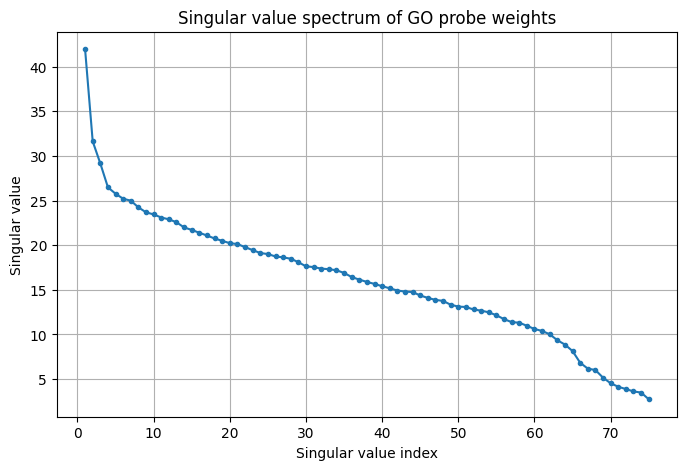

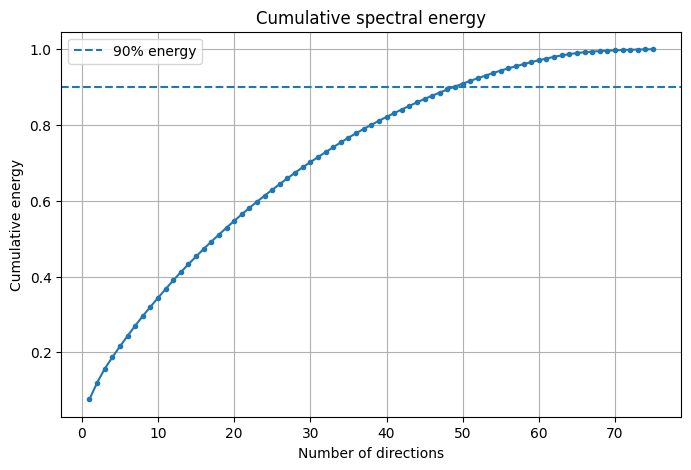

In [68]:
import numpy as np
import matplotlib.pyplot as plt

# Singular values of the probe weight matrix.
s = np.linalg.svd(W, compute_uv=False)

# Squared singular values are the energy carried by each direction.
energy = s**2
energy_ratio = energy / energy.sum()
cumulative_energy = np.cumsum(energy_ratio)

# Print the first 20 singular values and their share of the total energy.
print("First 20 singular values:")
print(np.round(s[:20], 4))

print("\nCumulative energy:")
for k in [1, 5, 10, 20, 30, 40, 50, 60, 75]:
    print(f"Top {k:2d} directions: {cumulative_energy[k-1]:.4%}")

# Plot the singular-value spectrum.
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(s) + 1), s, marker="o", markersize=3)
plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("Singular value spectrum of GO probe weights")
plt.grid(True)
plt.show()

# Plot the cumulative energy.
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(s) + 1), cumulative_energy, marker="o", markersize=3)
plt.axhline(0.90, linestyle="--", label="90% energy")
plt.xlabel("Number of directions")
plt.ylabel("Cumulative energy")
plt.title("Cumulative spectral energy")
plt.legend()
plt.grid(True)
plt.show()

### 6.2 Cumulative energy

The cumulative energy curve makes the concentration concrete: 90% of the energy
sits in 49 directions, 95% in 57 and 99% in 66, out of the 75 available. If the
weight vectors were isotropic the curve would be close to linear.

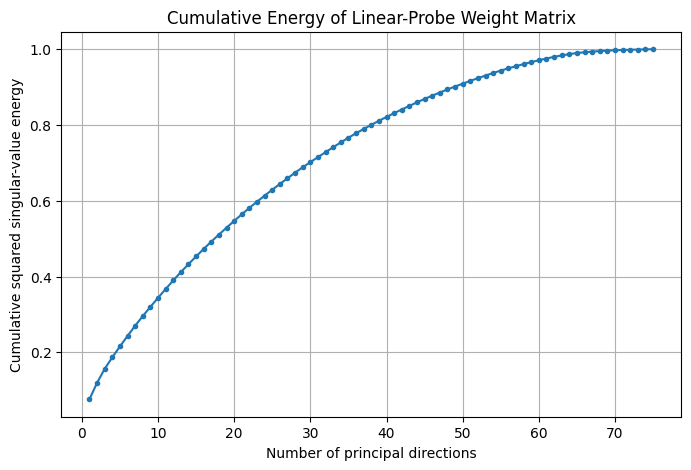

80% energy: 38 directions
90% energy: 49 directions
95% energy: 57 directions
99% energy: 66 directions


In [40]:
import matplotlib.pyplot as plt

U, S, Vt = np.linalg.svd(W, full_matrices=False)

energy = S**2
cumulative_energy = np.cumsum(energy) / np.sum(energy)

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(S) + 1),
    cumulative_energy,
    marker="."
)
plt.xlabel("Number of principal directions")
plt.ylabel("Cumulative squared singular-value energy")
plt.title("Cumulative Energy of Linear-Probe Weight Matrix")
plt.grid(True)
plt.show()

for threshold in [0.80, 0.90, 0.95, 0.99]:
    rank_needed = np.searchsorted(cumulative_energy, threshold) + 1
    print(f"{threshold:.0%} energy: {rank_needed} directions")

### 6.3 Effective rank and weight-vector similarity

The effective rank `exp(entropy of the energy distribution)` summarises the
spectrum in one number: 54.54 out of a possible 75, so the weights behave as if
they lived in roughly 55 dimensions rather than 75.

The cosine-similarity matrix shows which labels share a direction. The mean
off-diagonal cosine is 0.0426, close to orthogonal on average, but individual pairs
reach +0.42 (for example `GO:0005789` / `GO:0005783`, both endoplasmic-reticulum
terms) and -0.16 (nucleus vs. extracellular exosome), so the similarity structure
is not noise.

Effective rank: 54.54
Maximum possible rank: 75
Mean off-diagonal cosine similarity: 0.0426


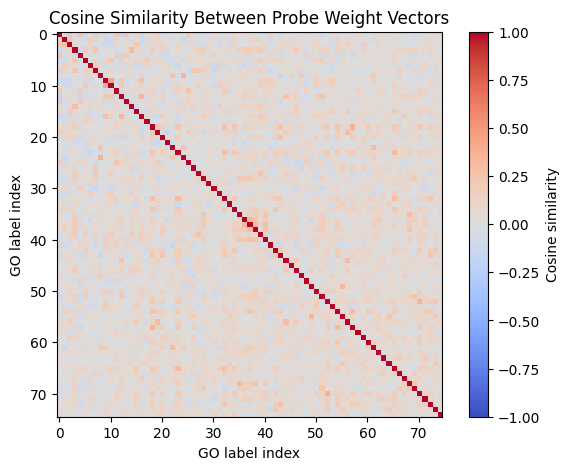

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# W has shape (75, 480): one probe direction per GO label.
singular_values = np.linalg.svd(W, compute_uv=False)

# Squared singular values are the energy carried by each direction.
energy = singular_values**2
p = energy / energy.sum()

# Effective rank: exp(entropy) of the energy distribution.
effective_rank = np.exp(-np.sum(p * np.log(p + 1e-12)))

# Normalise each label's weight vector and compute pairwise cosine similarity.
W_norm = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-12)
cosine_sim = W_norm @ W_norm.T

print(f"Effective rank: {effective_rank:.2f}")
print(f"Maximum possible rank: {min(W.shape)}")
print(f"Mean off-diagonal cosine similarity: "
      f"{(cosine_sim.sum() - np.trace(cosine_sim)) / (len(W) * (len(W)-1)):.4f}")

plt.figure(figsize=(7, 5))
plt.imshow(cosine_sim, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Cosine similarity")
plt.xlabel("GO label index")
plt.ylabel("GO label index")
plt.title("Cosine Similarity Between Probe Weight Vectors")
plt.show()

### 6.4 Numerical rank

The spectrum above says the energy is concentrated, not that the vectors are
linearly dependent. This cell computes the numerical rank of the full matrix and
finds it to be 75, i.e. the 75 probe directions are linearly independent and the
concentration is a matter of *angle and magnitude*, not redundancy.

In [66]:
import numpy as np

# W has shape (75, 480).
print("W shape:", W.shape)

# Numerical rank of the full set of weight vectors.
singular_values = np.linalg.svd(W, compute_uv=False)

tol = (
    max(W.shape)
    * np.finfo(float).eps
    * singular_values[0]
)

rank_W = np.sum(singular_values > tol)

print("Numerical rank of W:", rank_W)
print("Number of vectors:", W.shape[0])
print("Rank deficiency:", W.shape[0] - rank_W)

W shape: (75, 480)
Numerical rank of W: 75
Number of vectors: 75
Rank deficiency: 0


### 6.5 Rank of random subsets

To confirm that the full-rank result is not an artefact of having 75 vectors in 480
dimensions, the same rank test is repeated on random subsets of size 2 to 75. Every
subset is full rank, so no subset of labels is degenerate.

In [67]:
rng = np.random.default_rng(42)

for M in [2, 3, 5, 10, 20, 40, 75]:
    ranks = []

    for _ in range(100):
        idx = rng.choice(W.shape[0], size=M, replace=False)
        V = W[idx, :]

        s = np.linalg.svd(V, compute_uv=False)
        tol = max(V.shape) * np.finfo(float).eps * s[0]
        rank_V = np.sum(s > tol)

        ranks.append(rank_V)

    print(
        f"M={M:2d}: "
        f"mean rank={np.mean(ranks):.2f}, "
        f"rank-deficient subsets="
        f"{np.sum(np.array(ranks) < M)}/100"
    )

M= 2: mean rank=2.00, rank-deficient subsets=0/100
M= 3: mean rank=3.00, rank-deficient subsets=0/100
M= 5: mean rank=5.00, rank-deficient subsets=0/100
M=10: mean rank=10.00, rank-deficient subsets=0/100
M=20: mean rank=20.00, rank-deficient subsets=0/100
M=40: mean rank=40.00, rank-deficient subsets=0/100
M=75: mean rank=75.00, rank-deficient subsets=0/100


### 6.6 Isotropic random baseline

A quick null model: draw Gaussian matrices with the same shape and the same row
norms as `W`, and recompute the number of directions needed for 90% energy. The
observed value (49) is below the random baseline (mean 51.96, interval 51-52), and
none of the 500 random matrices is as concentrated. This suggests the probe weights
are more structured than random directions of the same magnitude.

In [42]:
rng = np.random.default_rng(42)

def directions_for_energy(matrix, threshold=0.90):
    s = np.linalg.svd(matrix, compute_uv=False)
    e = s**2
    return np.searchsorted(np.cumsum(e) / e.sum(), threshold) + 1

observed = directions_for_energy(W, 0.90)

row_norms = np.linalg.norm(W, axis=1)
n_simulations = 500
random_ranks = []

for _ in range(n_simulations):
    random_W = rng.normal(size=W.shape)
    random_W /= np.linalg.norm(random_W, axis=1, keepdims=True) + 1e-12
    random_W *= row_norms[:, None]

    random_ranks.append(directions_for_energy(random_W, 0.90))

random_ranks = np.array(random_ranks)

print("Observed directions for 90% energy:", observed)
print("Random baseline mean:", random_ranks.mean())
print("Random baseline 2.5%-97.5% interval:",
      np.percentile(random_ranks, [2.5, 97.5]))
print("Fraction of random matrices with rank <= observed:",
      np.mean(random_ranks <= observed))

Observed directions for 90% energy: 49
Random baseline mean: 51.962
Random baseline 2.5%-97.5% interval: [51. 52.]
Fraction of random matrices with rank <= observed: 0.0


### 6.7 Full isotropic null

The same comparison with 1,000 draws and two statistics. The observed rank90 (49)
and effective rank (54.54) both fall below the null means (51.96 and 60.91), so the
probe spectrum is more concentrated than an isotropic weight matrix with identical
row norms.

This baseline is deliberately lenient: it keeps the row norms but ignores the
correlation structure of the labels, which section 8 identifies as the dominant
factor.

In [52]:
import numpy as np

# W has shape (n_labels, embedding_dim): each row is one GO label's probe weights.

def spectral_profile(W):
    """Concentration metrics and normalised spectrum of a weight matrix."""
    singular_values = np.linalg.svd(
        W, full_matrices=False, compute_uv=False
    )
    energy = singular_values ** 2
    proportions = energy / energy.sum()
    cumulative = np.cumsum(proportions)

    # Shannon effective rank.
    p = proportions[proportions > 0]
    effective_rank = np.exp(-np.sum(p * np.log(p)))

    return {
        "rank90": int(np.searchsorted(cumulative, 0.90) + 1),
        "rank95": int(np.searchsorted(cumulative, 0.95) + 1),
        "effective_rank": effective_rank,
        "spectrum": proportions,
    }


def isotropic_null(W, n_perm=1000, seed=42):
    """Gaussian null matrices with the same row norms as W."""
    rng = np.random.default_rng(seed)
    row_norms = np.linalg.norm(W, axis=1)
    results = []

    for _ in range(n_perm):
        random_W = rng.normal(size=W.shape)
        random_W /= np.maximum(
            np.linalg.norm(random_W, axis=1, keepdims=True),
            1e-12
        )
        random_W *= row_norms[:, None]
        results.append(spectral_profile(random_W))

    return results


observed = spectral_profile(W)
null_results = isotropic_null(W, n_perm=1000)

null_rank90 = np.array([x["rank90"] for x in null_results])
null_erank = np.array([
    x["effective_rank"] for x in null_results
])

print("Observed rank90:", observed["rank90"])
print("Null rank90 mean:", null_rank90.mean())
print("Null rank90 2.5%-97.5%:",
      np.quantile(null_rank90, [0.025, 0.975]))

print("Observed effective rank:", observed["effective_rank"])
print("Null effective rank mean:", null_erank.mean())
print("Null effective rank 2.5%-97.5%:",
      np.quantile(null_erank, [0.025, 0.975]))

Observed rank90: 49
Null rank90 mean: 51.959
Null rank90 2.5%-97.5%: [51. 52.]
Observed effective rank: 54.53968
Null effective rank mean: 60.90574678456129
Null effective rank 2.5%-97.5%: [60.66484414 61.14165001]


## 7. Label co-occurrence vs. probe geometry

GO terms are not independent: related cellular components are annotated together,
and mutually exclusive ones almost never co-occur. This section asks whether the
geometry of the probe weights simply mirrors that label structure.

Three quantities are compared over all 2,775 label pairs:

- `cooccurrence`: number of proteins annotated with both terms,
- `label_corr`: Pearson correlation of the two label columns,
- `weight_cosine`: cosine similarity of the two probe weight vectors.

### 7.1 Co-occurrence, correlation and cosine tables

Compute the three pairwise quantities and rank the label pairs. The most aligned
weight vectors belong to terms that are biologically adjacent (endoplasmic
reticulum membrane vs. endoplasmic reticulum, presynaptic vs. postsynaptic
membrane, glutamatergic synapse vs. postsynapse), while the most anti-aligned pair
is nucleus vs. extracellular exosome, two compartments that rarely share a
protein.

In [43]:
import numpy as np
import pandas as pd

# 1. Number of proteins on which two GO terms co-occur.
cooccurrence = Y.T @ Y

# 2. Pearson correlation between label columns (rows are proteins).
label_corr = np.corrcoef(Y, rowvar=False)
label_corr = np.nan_to_num(label_corr, nan=0.0)

# 3. Cosine similarity between probe weight vectors.
W_norm = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-12)
weight_cosine = W_norm @ W_norm.T

# 4. Collect every label pair, excluding self-pairs from the ranking.
label_names = selected_labels
pairs = []

for i in range(len(label_names)):
    for j in range(i + 1, len(label_names)):
        pairs.append({
            "GO_label_1": label_names[i],
            "GO_label_2": label_names[j],
            "weight_cosine": weight_cosine[i, j],
            "label_correlation": label_corr[i, j],
            "cooccurrence_count": int(cooccurrence[i, j]),
        })

pair_df = pd.DataFrame(pairs)

print("Most similar weight-vector pairs:")
display(
    pair_df.sort_values("weight_cosine", ascending=False).head(15)
)

print("Most negatively aligned weight-vector pairs:")
display(
    pair_df.sort_values("weight_cosine", ascending=True).head(10)
)

Most similar weight-vector pairs:


,GO_label_1,GO_label_2,weight_cosine,label_correlation,cooccurrence_count
630,GO:0005789,GO:0005783,0.417674,0.405661,332
2539,GO:0045211,GO:0042734,0.357422,0.360950,44
1217,GO:0098978,GO:0098794,0.355723,0.318260,71
579,GO:0005739,GO:0005759,0.353873,0.497838,272
2455,GO:0015629,GO:0030027,0.336913,0.235968,34
825,GO:0005794,GO:0000139,0.331416,0.407077,226
2034,GO:0010008,GO:0005768,0.322046,0.229724,51
1490,GO:0030425,GO:0043204,0.310570,0.333495,63
2027,GO:0005764,GO:0005770,0.309987,0.312416,50
2567,GO:0098793,GO:0098794,0.303911,0.245044,33


Most negatively aligned weight-vector pairs:


,GO_label_1,GO_label_2,weight_cosine,label_correlation,cooccurrence_count
6,GO:0005634,GO:0070062,-0.160894,-0.059104,391
15,GO:0005634,GO:0000139,-0.160238,-0.105929,51
11,GO:0005634,GO:0005794,-0.151146,-0.082442,107
342,GO:0005654,GO:0098794,-0.143470,-0.020157,20
81,GO:0005829,GO:0005789,-0.143451,-0.078240,154
445,GO:0005576,GO:0030425,-0.139242,-0.019314,32
297,GO:0005654,GO:0005794,-0.137253,-0.089570,48
598,GO:0005739,GO:0014069,-0.133667,-0.023078,7
1415,GO:0005743,GO:0016604,-0.131927,-0.024533,0
96,GO:0005829,GO:0005759,-0.131746,-0.036361,69


### 7.2 Weight similarity vs. label correlation

Scatter the two quantities over all label pairs and measure the monotone
association. Spearman's rho is 0.507 (p about 1.7e-181), so labels that are
annotated together also receive similar probe directions.

Number of label pairs: 2775
Spearman correlation: 0.5074
P-value: 1.701e-181


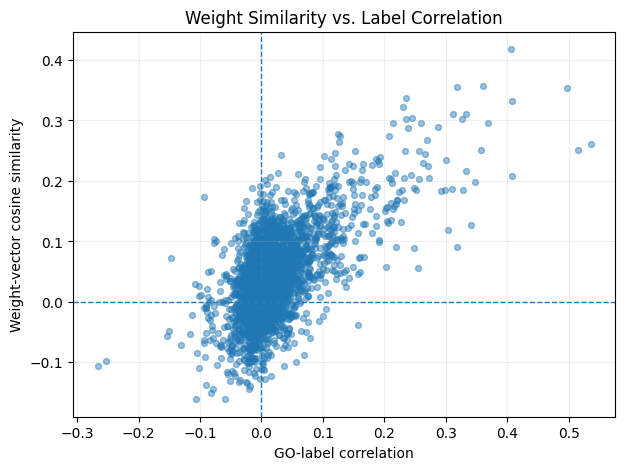

In [44]:
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt
import numpy as np

# Use the upper triangle only: each label pair is counted once.
i, j = np.triu_indices(len(selected_labels), k=1)

cosines = weight_cosine[i, j]
correlations = label_corr[i, j]
cooccurrences = cooccurrence[i, j]

# 1. Weight similarity vs. label co-annotation.
rho, p_value = spearmanr(cosines, correlations)

print("Number of label pairs:", len(cosines))
print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {p_value:.3e}")

# 2. Scatter plot of the two quantities.
plt.figure(figsize=(7, 5))
plt.scatter(correlations, cosines, alpha=0.45, s=18)
plt.axhline(0, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("GO-label correlation")
plt.ylabel("Weight-vector cosine similarity")
plt.title("Weight Similarity vs. Label Correlation")
plt.grid(alpha=0.2)
plt.show()

### 7.3 Partial rank correlation

Co-annotated labels share co-occurrence counts, which inflates the raw
correlation. This cell residualises both rank-transformed variables on
`log(1 + cooccurrence)` and correlates the residuals. The partial correlation is
0.487, so the association is not an artefact of co-occurrence alone.

In [47]:
import numpy as np
from scipy.stats import spearmanr

# Upper triangle only, so each pair is counted once.
i, j = np.triu_indices(len(selected_labels), k=1)

cosines = weight_cosine[i, j]
correlations = label_corr[i, j]
counts = cooccurrence[i, j]

# Rank-transform the variables to keep the analysis monotone.
from scipy.stats import rankdata

rank_features = np.column_stack([
    rankdata(correlations),
    rankdata(np.log1p(counts))
])
y = rankdata(cosines)

# Control for co-occurrence count: residualise both y and the correlation on it.
X_design = np.column_stack([np.ones(len(y)), rank_features[:, 1]])
resid_y = y - X_design @ np.linalg.lstsq(
    X_design, y, rcond=None
)[0]

resid_corr = rank_features[:, 0] - X_design @ np.linalg.lstsq(
    X_design, rank_features[:, 0], rcond=None
)[0]

rho_partial, _ = spearmanr(resid_y, resid_corr)
print("Partial rank correlation:", rho_partial)

Partial rank correlation: 0.4872280648593841


### 7.4 Partial correlation with a p-value

The same partial analysis with a p-value. The nominal value (p about 1e-166)
confirms that weight similarity tracks label correlation after controlling for
co-occurrence. Note that the pairs are not independent, so the p-value is
descriptive rather than a formal test.

In [50]:
import numpy as np
from scipy.stats import rankdata, pearsonr

i, j = np.triu_indices(len(selected_labels), k=1)

y = rankdata(weight_cosine[i, j])
x = rankdata(label_corr[i, j])
n = rankdata(np.log1p(cooccurrence[i, j]))

# Design matrix: intercept plus the co-occurrence control variable.
Z = np.column_stack([
    np.ones(len(y)),
    n
])

# Residualise both y and x on the co-occurrence count.
resid_y = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
resid_x = x - Z @ np.linalg.lstsq(Z, x, rcond=None)[0]

rho_partial, p_partial = pearsonr(resid_x, resid_y)

print(f"Partial Spearman correlation: {rho_partial:.4f}")
print(f"Nominal p-value: {p_partial:.3e}")

Partial Spearman correlation: 0.4889
Nominal p-value: 1.010e-166


## 8. Null models and permutation tests

Sections 6 asked whether the probe weights are more concentrated than random
vectors. This section asks a sharper question: is the concentration explained by
*the labels themselves*? Two permutation schemes are used.

- **Label shuffle**: shuffle each label column independently, destroying the
  co-occurrence structure while keeping each label's number of positives, then
  refit the probe.
- **Row permutation**: permute the rows of the training label matrix as a block,
  which keeps the co-occurrence structure but breaks the pairing with sequences.

If the observed spectrum is indistinguishable from these nulls, the geometry of
`W` is a property of the annotation structure rather than of the sequence
representation.

### 8.1 Refitting helpers

`train_probe_and_get_W` rebuilds the exact probe from section 5 and returns its
weight matrix; `spectral_metrics` returns the effective rank and rank90. Using the
same hyper-parameters as the main model keeps the comparison fair.

In [54]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

# Label-permutation test: retrain the probe on shuffled labels.


def train_probe_and_get_W(X_data, Y_data):
    """Fit the OvR logistic probe and return the stacked weight matrix."""
    model = make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            LogisticRegression(
                C=1.0,
                max_iter=1000,
                class_weight="balanced"
            ),
            n_jobs=-1
        )
    )

    model.fit(X_data, Y_data)

    ovr = model.named_steps["onevsrestclassifier"]
    W_out = np.vstack([
        clf.coef_.ravel()
        for clf in ovr.estimators_
    ])

    return W_out


def spectral_metrics(W_in):
    """Return (effective rank, rank90) for one weight matrix."""
    s = np.linalg.svd(W_in, compute_uv=False)
    energy = s ** 2
    p = energy / energy.sum()

    effective_rank = np.exp(
        -np.sum(p * np.log(p + 1e-12))
    )

    rank90 = np.searchsorted(
        np.cumsum(p), 0.90
    ) + 1

    return effective_rank, rank90

### 8.2 Label-shuffle experiment

Each of the 200 iterations shuffles every label column independently and refits the
probe on the same training embeddings. Two variants are recorded: the raw shuffled
weights (A) and the shuffled weights rescaled to the true row norms (B), which
separates a change in direction from a change in magnitude. On CPU this takes about
6.5 minutes.

In [58]:
from tqdm.auto import tqdm

N_PERMUTATIONS = 200
rng = np.random.default_rng(42)

# Weight matrix and metrics for the true labels.
W_observed = W.copy()

observed_er, observed_rank90 = spectral_metrics(W_observed)

# Results of the label-shuffle experiment.
permuted_er = []
permuted_rank90 = []

# Results after rescaling each row to the true L2 norm.
matched_er = []
matched_rank90 = []

original_norms = np.linalg.norm(
    W_observed, axis=1
)

for iteration in tqdm(range(N_PERMUTATIONS)):
    Y_shuffled = Y_train.copy()

    # Shuffle each label column separately, keeping its number of positives.
    for j in range(Y_shuffled.shape[1]):
        Y_shuffled[:, j] = rng.permutation(
            Y_shuffled[:, j]
        )

    # Refit on the same training embeddings.
    W_perm = train_probe_and_get_W(
        X_train, Y_shuffled
    )

    # A: compare the weight matrix trained on shuffled labels directly.
    er, r90 = spectral_metrics(W_perm)
    permuted_er.append(er)
    permuted_rank90.append(r90)

    # B: rescale each row to the true weight vector's L2 norm.
    perm_norms = np.linalg.norm(
        W_perm, axis=1, keepdims=True
    )

    W_perm_matched = (
        W_perm / np.maximum(perm_norms, 1e-12)
    ) * original_norms[:, None]

    er_matched, r90_matched = spectral_metrics(
        W_perm_matched
    )
    matched_er.append(er_matched)
    matched_rank90.append(r90_matched)

print("Permutation experiment complete.")

100%|█████████████████████████████████████████████████████████████████████████████████| 200/200 [06:34<00:00,  1.97s/it]

Permutation experiment complete.


### 8.3 Summarise the label-shuffle null

For each statistic the empirical lower-tail p-value is
`(1 + #{null <= observed}) / (1 + B)`. A small value means the observed spectrum is
more concentrated than the shuffled-label null.

In [ ]:
def summarize_null(name, values, observed):
    values = np.asarray(values)

    print(f"\n{name}")
    print(f"Observed: {observed:.3f}")
    print(f"Null mean: {values.mean():.3f}")
    print(
        "Null 95% interval:",
        np.percentile(values, [2.5, 97.5])
    )

    # Low effective rank / low rank90 means a more concentrated spectrum.
    p_empirical = (
        1 + np.sum(values <= observed)
    ) / (len(values) + 1)

    print(
        "Empirical lower-tail p-value:",
        round(p_empirical, 4)
    )


summarize_null(
    "Effective rank: raw shuffled weights",
    permuted_er,
    observed_er
)

summarize_null(
    "Rank90: raw shuffled weights",
    permuted_rank90,
    observed_rank90
)

summarize_null(
    "Effective rank: row-norm-matched weights",
    matched_er,
    observed_er
)

summarize_null(
    "Rank90: row-norm-matched weights",
    matched_rank90,
    observed_rank90
)

### 8.4 Row-permutation null

The second null permutes the rows of `Y_train` as a block, so label co-occurrence
patterns are preserved but no longer attached to the right sequences. The probe is
refit 100 times and each weight matrix is row-norm-matched before measuring.

Result: effective rank 54.32 (95% interval 53.57-54.98) against an observed 54.54
(p = 0.73), and rank90 47.98 against an observed 49 (p = 1.00, i.e. the observed
matrix is if anything slightly *less* concentrated than the null). The observed
spectrum is therefore indistinguishable from this null: the concentration seen in
section 6 is what the label co-occurrence structure alone produces when the probe
is fitted to those targets.

In [63]:
N_ROW_PERMUTATIONS = 100
rng = np.random.default_rng(2026)

row_perm_er = []
row_perm_rank90 = []

original_norms = np.linalg.norm(W, axis=1)

for iteration in range(N_ROW_PERMUTATIONS):
    # Permute the rows of the label matrix as a block, which preserves the
    # co-occurrence structure between labels.
    perm = rng.permutation(len(Y_train))
    Y_perm = Y_train[perm]

    W_perm = train_probe_and_get_W(X_train, Y_perm)

    # Match the L2 norm of every weight vector.
    perm_norms = np.linalg.norm(
        W_perm, axis=1, keepdims=True
    )

    W_perm_matched = (
        W_perm / np.maximum(perm_norms, 1e-12)
    ) * original_norms[:, None]

    er, r90 = spectral_metrics(W_perm_matched)

    row_perm_er.append(er)
    row_perm_rank90.append(r90)

def report_lower_tail(observed, null_values):
    null_values = np.asarray(null_values)
    p_emp = (
        1 + np.sum(null_values <= observed)
    ) / (len(null_values) + 1)

    print(f"Observed: {observed:.3f}")
    print(f"Null mean: {null_values.mean():.3f}")
    print(
        "95% interval:",
        np.percentile(null_values, [2.5, 97.5])
    )
    print(f"Empirical lower-tail p-value: {p_emp:.4f}")

print("Effective rank - row permutation")
report_lower_tail(observed_er, row_perm_er)

print("\nRank90 - row permutation")
report_lower_tail(observed_rank90, row_perm_rank90)

Effective rank — row permutation
Observed: 54.540
Null mean: 54.322
95% interval: [53.56742506 54.98262196]
Empirical lower-tail p-value: 0.7327

Rank90 — row permutation
Observed: 49.000
Null mean: 47.980
95% interval: [48. 48.]
Empirical lower-tail p-value: 1.0000


## 9. Artifact inventory

Everything the notebook writes lives in `protein_dataset/`. This section prints
the shape and dtype of each file so a later session can start from section 5
without re-downloading or re-embedding anything. `protein_dataset/README.md`
documents the same files in more detail.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

data_dir = Path("protein_dataset")

# Files written by this notebook, grouped by their role in the pipeline.
inventory = {
    "Protein table": ["uniprot_swissprot_go_cc.csv"],
    "Label bookkeeping": [
        "go_cc_label_counts.csv",
        "selected_go_labels.csv",
    ],
    "Model inputs": [
        "esm2_embeddings.npy",
        "go_labels.npy",
        "protein_ids.csv",
    ],
}

for group, names in inventory.items():
    print(f"\n{'=' * 18} {group} {'=' * 18}")
    for name in names:
        path = data_dir / name
        print(f"\n{path}")
        print("Exists:", path.exists())
        if not path.exists():
            continue

        if path.suffix == ".csv":
            table = pd.read_csv(path)
            print("Shape:", table.shape)
            print("Columns:", table.columns.tolist())
        else:
            array = np.load(path, mmap_mode="r")
            print("Shape:", array.shape)
            print("Dtype:", array.dtype)


================== Protein table ==================

protein_dataset/uniprot_swissprot_go_cc.csv
Exists: True
Shape: (9895, 3)
Columns: ['uniprot_id', 'sequence', 'go_cc_raw']

================== Label bookkeeping ==================

protein_dataset/go_cc_label_counts.csv
Exists: True
Shape: (1779, 2)
Columns: ['go_id', 'protein_count']

protein_dataset/selected_go_labels.csv
Exists: True
Shape: (75, 1)
Columns: ['go_id']

================== Model inputs ==================

protein_dataset/esm2_embeddings.npy
Exists: True
Shape: (9895, 480)
Dtype: float32

protein_dataset/go_labels.npy
Exists: True
Shape: (9895, 75)
Dtype: float32

protein_dataset/protein_ids.csv
Exists: True
Shape: (9895, 1)
Columns: ['uniprot_id']


In [ ]:
print("Files in protein_dataset:")
for path in sorted(data_dir.iterdir()):
    print(path.name, f"({path.stat().st_size:,} bytes)")

Files in protein_dataset:
.ipynb_checkpoints (160 bytes)
README.md (2,796 bytes)
esm2_embeddings.npy (18,998,528 bytes)
go_cc_label_counts.csv (23,703 bytes)
go_labels.npy (2,968,628 bytes)
protein_ids.csv (69,308 bytes)
selected_go_labels.csv (831 bytes)
uniprot_swissprot_go_cc.csv (7,870,434 bytes)


## 10. Summary and limitations

**What the notebook establishes**

- A one-vs-rest logistic probe on frozen mean-pooled ESM-2 embeddings predicts 75
  GO CC terms with mean ROC-AUC 0.784 and mean average precision 0.223 on a held-out
  20% split.
- The probe's 75 x 480 weight matrix is linearly independent (numerical rank 75),
  yet its energy is concentrated: 49 directions cover 90% of it and the effective
  rank is 54.5 rather than 75.
- Isotropic Gaussian nulls with matched row norms are less concentrated (rank90 52,
  effective rank 60.9), so the weights are not random directions.
- That concentration is, however, explained by the label structure: a row-permutation
  null that preserves GO co-occurrence reproduces the observed spectrum
  (effective rank 54.3 vs 54.5, p = 0.73).
- Weight-vector similarity still tracks label co-annotation after controlling for
  co-occurrence (partial Spearman correlation 0.49), so the geometry carries
  semantic information even though its global concentration does not go beyond
  what the label distribution implies.

**Limitations**

- The download is capped at 10,000 records, so the dataset is a prefix of reviewed
  Swiss-Prot rather than the full database; absolute metrics are therefore not
  comparable across papers.
- The probe uses a single frozen layer and mean pooling; other layers or pooling
  schemes may change both accuracy and geometry.
- The split is a single 80/20 hold-out with no stratification or cross-validation,
  and no ontology-aware propagation of parent terms.
- Labels with exactly 100 positives remain difficult, which is why average
  precision is much lower than ROC-AUC.
- The permutation tests reuse one seed and a fixed probe configuration; the
  conclusions are conditional on that configuration.

**Natural next steps**

1. Replace the flat classifier with a hierarchy-aware head over the GO DAG.
2. Compare probes across ESM-2 layers and pooling strategies.
3. Repeat the spectral analysis for a larger ESM-2 checkpoint and for a
   sequence-only baseline without pretraining.
4. Use repeated cross-validation and report per-label metrics with confidence
   intervals.